In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
df = pd.read_csv("diabetes_young_adults.csv")
target = "Diabetes_binary"

In [3]:
print(df.shape)
print(df.dtypes.value_counts())
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.head()

(24421, 22)
float64    22
Name: count, dtype: int64
Missing: 0
Duplicates: 1823


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,15.0,0.0,0.0,0.0,2.0,6.0,7.0
1,0.0,0.0,1.0,1.0,27.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,1.0,5.0,4.0
2,0.0,0.0,1.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,7.0,2.0,0.0,0.0,1.0,5.0,8.0
3,0.0,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,5.0,0.0,0.0,0.0,3.0,6.0,8.0
4,1.0,0.0,0.0,1.0,32.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,4.0,0.0,3.0,0.0,0.0,3.0,5.0,3.0


Diabetes_binary
0.0    23889
1.0      532
Name: count, dtype: int64
Diabetes_binary
0.0    97.821547
1.0     2.178453
Name: proportion, dtype: float64


C:\Users\sachi\AppData\Local\Temp\ipykernel_60092\3237727969.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No diabetes (0)", "Prediabetes/Diabetes (1)"])


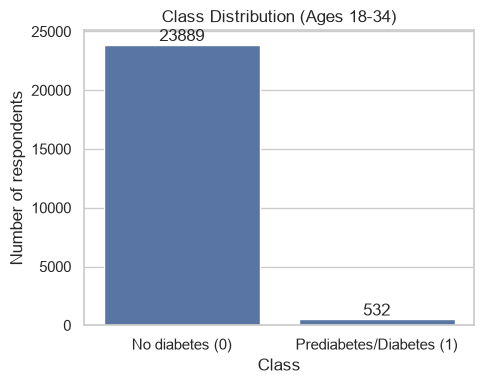

In [4]:
print(df[target].value_counts())
print(df[target].value_counts(normalize=True) * 100)

plt.figure(figsize=(5, 4))
ax = sns.countplot(x=target, data=df)
ax.set_xticklabels(["No diabetes (0)", "Prediabetes/Diabetes (1)"])
ax.set_title("Class Distribution (Ages 18-34)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of respondents")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=300)
plt.show()

                BMI      MentHlth      PhysHlth
count  24421.000000  24421.000000  24421.000000
mean      27.627820      3.946480      2.249376
std        7.405286      7.568121      5.777485
min       13.000000      0.000000      0.000000
25%       23.000000      0.000000      0.000000
50%       26.000000      0.000000      0.000000
75%       30.000000      4.000000      2.000000
max       98.000000     30.000000     30.000000


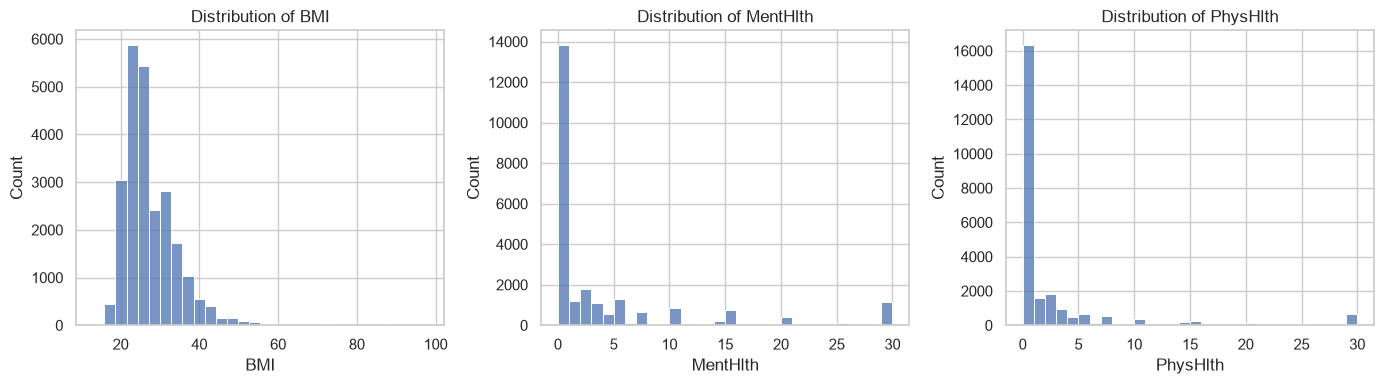

In [5]:
num_cols = ["BMI", "MentHlth", "PhysHlth"]
print(df[num_cols].describe())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("figures/02_numeric_distributions.png", dpi=300)
plt.show()

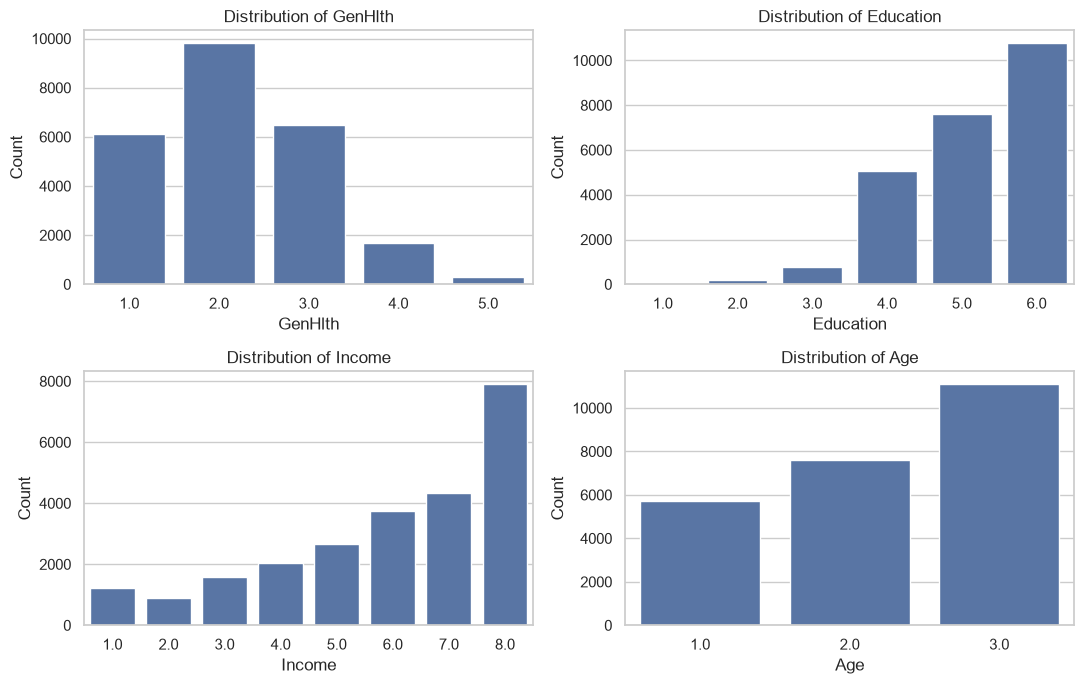

In [6]:
ord_cols = ["GenHlth", "Education", "Income", "Age"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ord_cols):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("figures/03_ordinal_distributions.png", dpi=300)
plt.show()

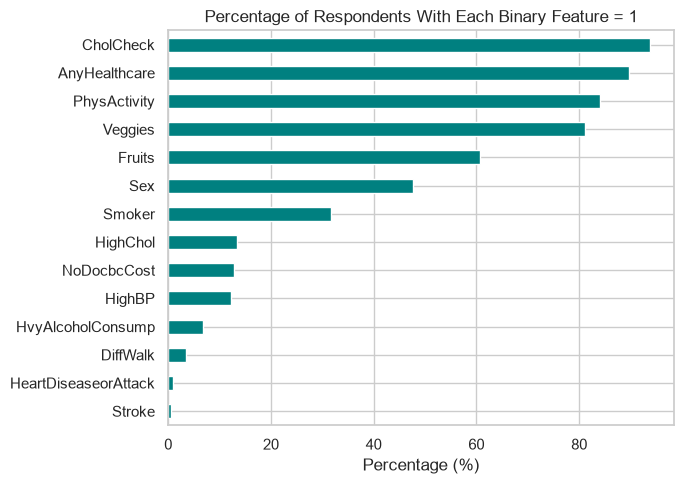

In [7]:
binary_cols = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
               "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
               "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
prev = (df[binary_cols].mean() * 100).sort_values()

plt.figure(figsize=(7, 5))
prev.plot(kind="barh", color="teal")
plt.title("Percentage of Respondents With Each Binary Feature = 1")
plt.xlabel("Percentage (%)")
plt.tight_layout()
plt.savefig("figures/04_binary_prevalence.png", dpi=300)
plt.show()

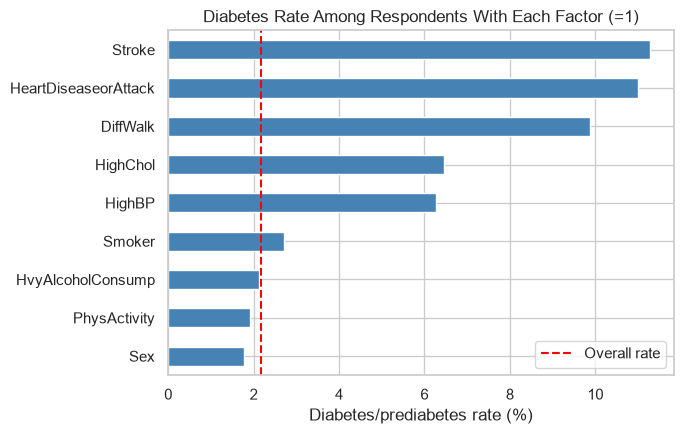

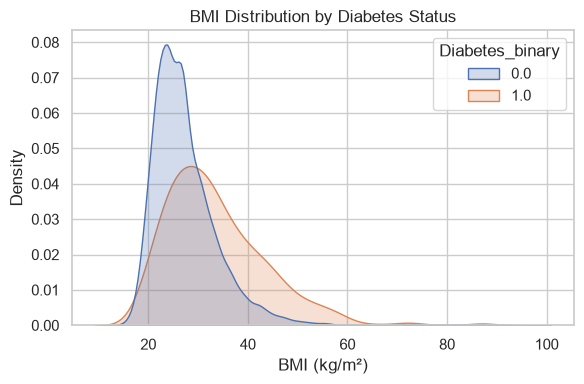

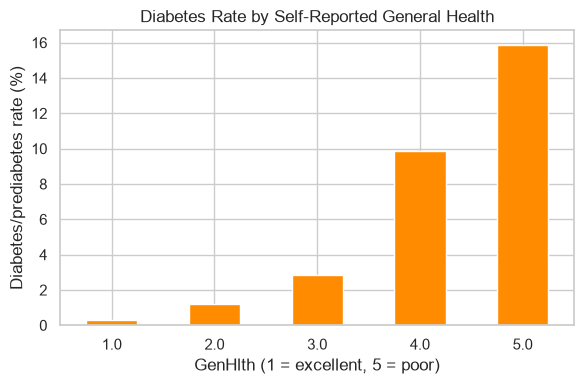

In [8]:
# Diabetes rate when each binary risk factor = 1
risk_cols = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack",
             "PhysActivity", "HvyAlcoholConsump", "DiffWalk", "Sex"]
rates = pd.Series({c: df[df[c] == 1][target].mean() * 100 for c in risk_cols}).sort_values()

plt.figure(figsize=(7, 4.5))
rates.plot(kind="barh", color="steelblue")
plt.axvline(df[target].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.title("Diabetes Rate Among Respondents With Each Factor (=1)")
plt.xlabel("Diabetes/prediabetes rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/05_positive_rate_binary.png", dpi=300)
plt.show()

# BMI by class
plt.figure(figsize=(6, 4))
sns.kdeplot(data=df, x="BMI", hue=target, common_norm=False, fill=True)
plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("BMI (kg/m²)")
plt.tight_layout()
plt.savefig("figures/06_bmi_by_class.png", dpi=300)
plt.show()

# General health by class
gh = df.groupby("GenHlth")[target].mean() * 100
plt.figure(figsize=(6, 4))
gh.plot(kind="bar", color="darkorange")
plt.title("Diabetes Rate by Self-Reported General Health")
plt.xlabel("GenHlth (1 = excellent, 5 = poor)")
plt.ylabel("Diabetes/prediabetes rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/07_genhlth_rate.png", dpi=300)
plt.show()

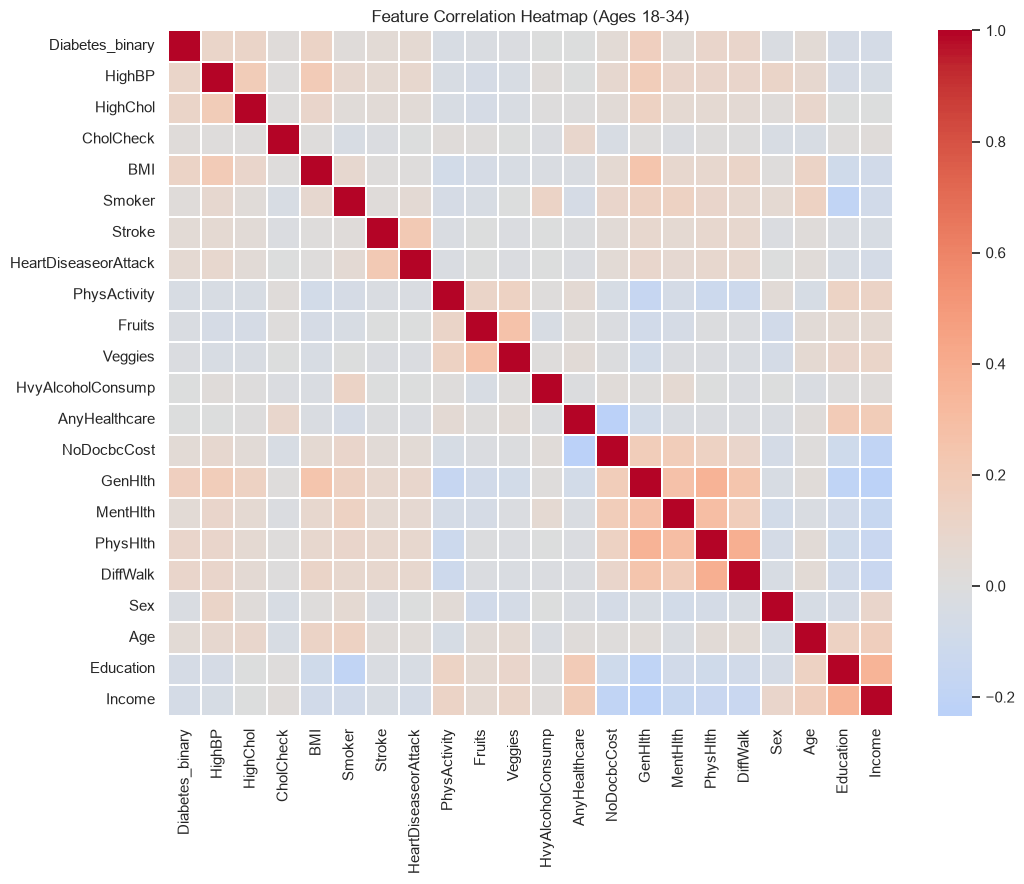

GenHlth                 0.162394
BMI                     0.119247
HighChol                0.115521
HighBP                  0.105356
PhysHlth                0.100521
DiffWalk                0.098861
HeartDiseaseorAttack    0.056175
MentHlth                0.046275
Stroke                  0.046128
NoDocbcCost             0.043214
Age                     0.041341
CholCheck               0.025692
Smoker                  0.025288
HvyAlcoholConsump      -0.000790
AnyHealthcare          -0.003950
Veggies                -0.019817
Fruits                 -0.024373
Sex                    -0.025950
PhysActivity           -0.043208
Education              -0.059753
Income                 -0.067412
Name: Diabetes_binary, dtype: float64


In [9]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation Heatmap (Ages 18-34)")
plt.tight_layout()
plt.savefig("figures/08_correlation_heatmap.png", dpi=300)
plt.show()

print(df.corr()[target].drop(target).sort_values(ascending=False))

In [10]:
import pandas as pd

df = pd.read_csv("diabetes_young_adults.csv")
target = "Diabetes_binary"

print("Duplicates in young subset:", df.duplicated().sum())
print("\nCorrelation with target:\n",
      df.corr()[target].drop(target).sort_values(ascending=False).round(3))

Duplicates in young subset: 1823

Correlation with target:
 GenHlth                 0.162
BMI                     0.119
HighChol                0.116
HighBP                  0.105
PhysHlth                0.101
DiffWalk                0.099
HeartDiseaseorAttack    0.056
MentHlth                0.046
Stroke                  0.046
NoDocbcCost             0.043
Age                     0.041
CholCheck               0.026
Smoker                  0.025
HvyAlcoholConsump      -0.001
AnyHealthcare          -0.004
Veggies                -0.020
Fruits                 -0.024
Sex                    -0.026
PhysActivity           -0.043
Education              -0.060
Income                 -0.067
Name: Diabetes_binary, dtype: float64
